# 1. Dataset Exploration und Analyse

In diesem Notebook analysieren wir das IMDB Movie Review Dataset:
- Dataset-Größe und Balance
- Text-Charakteristika (Länge, Wortanzahl, etc.)
- Visualisierungen


In [8]:
import subprocess
import sys

try:
    import seaborn
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "seaborn"])


In [ ]:
# Import der benötigten Bibliotheken
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore') 

# Basis-Verzeichnis des Projekts ermitteln
current_dir = Path().resolve()
if current_dir.name == 'src':
    BASE_DIR = current_dir.parent
else:
    BASE_DIR = current_dir

sys.path.insert(0, str(BASE_DIR / "src"))

# Import der benutzerdefinierten Funktionen für IMDB-Daten
from utils_imdb import read_imdb_split, basic_clean

plt.style.use('seaborn-v0_8')
sns.set_palette("husl")



BASE_DIR: C:\Users\zelih\JupyterProject\cvnlp-imdb-opinion-mining
DATA_ROOT wird sein: C:\Users\zelih\JupyterProject\cvnlp-imdb-opinion-mining\data\aclImdb


## 1.1 Daten laden


In [10]:
# Pfad zum IMDB-Datensatz definieren
DATA_ROOT = BASE_DIR / "data" / "aclImdb"
OUTPUT_DIR = BASE_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)  # Ausgabe-Verzeichnis erstellen falls nicht vorhanden

# Parameter für Datensatz-Laden:
MAX_DOCS_PER_CLASS = None  # Beispiel: 1000 für schnellere Testläufe

import glob
import os

# Konvertiere Path-Objekt zu String für glob
data_root_str = str(DATA_ROOT)
train_pos_files = glob.glob(os.path.join(data_root_str, "train", "pos", "*.txt"))
train_neg_files = glob.glob(os.path.join(data_root_str, "train", "neg", "*.txt"))
test_pos_files = glob.glob(os.path.join(data_root_str, "test", "pos", "*.txt"))
test_neg_files = glob.glob(os.path.join(data_root_str, "test", "neg", "*.txt"))

print(f"Train/pos: {len(train_pos_files)} Dateien")
print(f"Train/neg: {len(train_neg_files)} Dateien")
print(f"Test/pos: {len(test_pos_files)} Dateien")
print(f"Test/neg: {len(test_neg_files)} Dateien")

if len(train_pos_files) == 0 and len(train_neg_files) == 0:
    print("\n WARNUNG: Keine Trainingsdaten gefunden!")
    print(f"   Erwarteter Pfad: {DATA_ROOT / 'train'}")
    print("   Bitte stellen Sie sicher, dass die IMDB Trainingsdaten heruntergeladen wurden.")
    print("   Die Trainingsdaten sollten in folgenden Verzeichnissen sein:")
    print(f"   - {DATA_ROOT / 'train' / 'pos'} (positive Reviews)")
    print(f"   - {DATA_ROOT / 'train' / 'neg'} (negative Reviews)")

print("\n" + "="*60)
print("Lade Datensatz...")
# Trainings- und Testdaten laden
# Die Funktion read_imdb_split liest alle Reviews aus den Unterordnern (pos/neg)
train_df = read_imdb_split(DATA_ROOT / "train", max_docs_per_class=MAX_DOCS_PER_CLASS)
test_df = read_imdb_split(DATA_ROOT / "test", max_docs_per_class=MAX_DOCS_PER_CLASS)

# Größe der Datensätze ausgeben
print(f"\nTrainingsdaten: {len(train_df)} Reviews")
print(f"Testdaten: {len(test_df)} Reviews")
print(f"Gesamtgröße: {len(train_df) + len(test_df)} Reviews")


=== Debug: Prüfe verfügbare Dateien ===
DATA_ROOT: C:\Users\zelih\JupyterProject\cvnlp-imdb-opinion-mining\data\aclImdb
Existiert DATA_ROOT: True
Train/pos: 12500 Dateien
Train/neg: 12500 Dateien
Test/pos: 12500 Dateien
Test/neg: 12500 Dateien

Lade Datensatz...


Reading neg: 100%|████████████████████████| 12500/12500 [04:55<00:00, 42.23it/s]



Trainingsdaten: 25000 Reviews
Testdaten: 25000 Reviews
Gesamtgröße: 50000 Reviews


## 1.2 Dataset Balance


=== Trainingsdaten ===
label
1    12500
0    12500
Name: count, dtype: int64

Normalisiert (Anteile):
label
1    0.5
0    0.5
Name: proportion, dtype: float64

=== Testdaten ===
label
1    12500
0    12500
Name: count, dtype: int64

Normalisiert (Anteile):
label
1    0.5
0    0.5
Name: proportion, dtype: float64


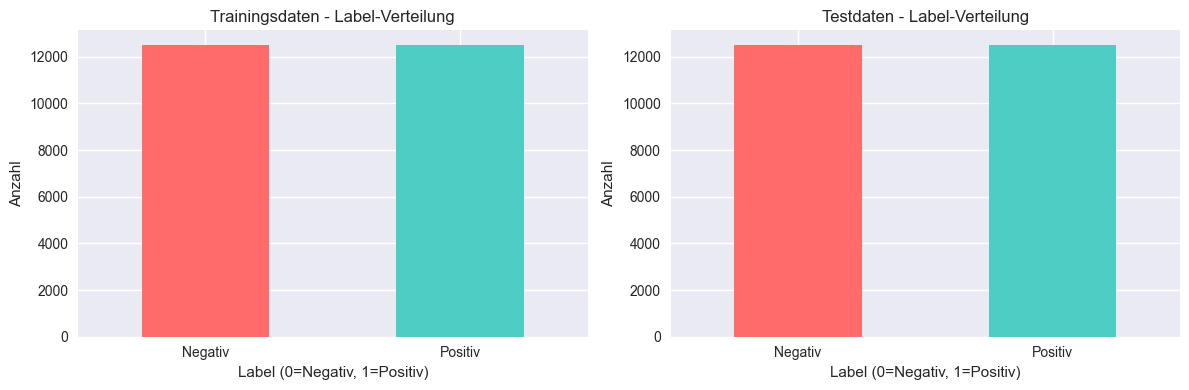


  Dataset ist BALANCIERT!


In [11]:
# Überprüfung der Label-Verteilung (Balance-Check)
# Ein balancierter Datensatz hat etwa gleich viele positive und negative Reviews
print("=== Trainingsdaten ===")
if len(train_df) > 0:
    print(train_df["label"].value_counts())
    print("\nNormalisiert (Anteile):")
    print(train_df["label"].value_counts(normalize=True))
else:
    print(" Keine Trainingsdaten vorhanden!")

print("\n=== Testdaten ===")
if len(test_df) > 0:
    print(test_df["label"].value_counts())
    print("\nNormalisiert (Anteile):")
    print(test_df["label"].value_counts(normalize=True))
else:
    print("Keine Testdaten vorhanden!")

# Visualisierung der Label-Verteilung
# Anzahl der Subplots basierend auf verfügbaren Daten bestimmen
num_plots = sum([len(train_df) > 0, len(test_df) > 0])

if num_plots > 0:
    fig, axes = plt.subplots(1, num_plots, figsize=(6 * num_plots, 4))
    if num_plots == 1:
        axes = [axes]  # Für einen einzelnen Subplot als Array konvertieren
    
    plot_idx = 0
    
    # Balkendiagramm für Trainingsdaten (falls vorhanden)
    if len(train_df) > 0:
        train_counts = train_df["label"].value_counts()
        if len(train_counts) > 0:
            train_counts.plot(kind="bar", ax=axes[plot_idx], color=['#ff6b6b', '#4ecdc4'])
            axes[plot_idx].set_title("Trainingsdaten - Label-Verteilung")
            axes[plot_idx].set_xlabel("Label (0=Negativ, 1=Positiv)")
            axes[plot_idx].set_ylabel("Anzahl")
            # Labels nur setzen, wenn beide Labels vorhanden sind
            if len(train_counts) == 2:
                axes[plot_idx].set_xticklabels(["Negativ", "Positiv"], rotation=0)
            elif len(train_counts) == 1:
                label_name = "Negativ" if train_counts.index[0] == 0 else "Positiv"
                axes[plot_idx].set_xticklabels([label_name], rotation=0)
        else:
            axes[plot_idx].text(0.5, 0.5, "Keine Daten", ha='center', va='center')
            axes[plot_idx].set_title("Trainingsdaten - Label-Verteilung")
        plot_idx += 1
    
    # Balkendiagramm für Testdaten (falls vorhanden)
    if len(test_df) > 0:
        test_counts = test_df["label"].value_counts()
        if len(test_counts) > 0:
            test_counts.plot(kind="bar", ax=axes[plot_idx], color=['#ff6b6b', '#4ecdc4'])
            axes[plot_idx].set_title("Testdaten - Label-Verteilung")
            axes[plot_idx].set_xlabel("Label (0=Negativ, 1=Positiv)")
            axes[plot_idx].set_ylabel("Anzahl")
            # Labels nur setzen, wenn beide Labels vorhanden sind
            if len(test_counts) == 2:
                axes[plot_idx].set_xticklabels(["Negativ", "Positiv"], rotation=0)
            elif len(test_counts) == 1:
                label_name = "Negativ" if test_counts.index[0] == 0 else "Positiv"
                axes[plot_idx].set_xticklabels([label_name], rotation=0)
        else:
            axes[plot_idx].text(0.5, 0.5, "Keine Daten", ha='center', va='center')
            axes[plot_idx].set_title("Testdaten - Label-Verteilung")
    
    plt.tight_layout()
    plt.savefig(BASE_DIR / "outputs" / "dataset_balance.png", dpi=300, bbox_inches='tight')
    plt.show()
else:
    print("\n Keine Daten zum Visualisieren vorhanden!")

# Automatische Balance-Prüfung: Wenn der Mittelwert nahe 0.5 liegt, ist der Datensatz balanciert
if len(train_df) > 0:
    is_balanced = abs(train_df["label"].mean() - 0.5) < 0.01
    print("\n  Dataset ist BALANCIERT!" if is_balanced else "\n  Dataset ist NICHT balanciert!")
else:
    print("\n Keine Trainingsdaten für Balance-Prüfung vorhanden!")


## 1.3 Text-Charakteristika


In [12]:
# Texte bereinigen (Kleinschreibung, Sonderzeichen entfernen, etc.)
if len(train_df) > 0:
    train_df["clean"] = train_df["text"].apply(basic_clean)
    # Textstatistiken berechnen:
    # - Wortanzahl: Anzahl der Wörter pro Review
    # - Zeichenanzahl: Anzahl der Zeichen pro Review
    # - Satzanzahl: Anzahl der Sätze pro Review (erkennbar an Satzzeichen)
    train_df["word_count"] = train_df["clean"].str.split().map(len)
    train_df["char_count"] = train_df["clean"].str.len()
    train_df["sentence_count"] = train_df["clean"].str.count(r'[.!?]+')  # Regex für Satzende

if len(test_df) > 0:
    test_df["clean"] = test_df["text"].apply(basic_clean)
    test_df["word_count"] = test_df["clean"].str.split().map(len)
    test_df["char_count"] = test_df["clean"].str.len()
    test_df["sentence_count"] = test_df["clean"].str.count(r'[.!?]+')

# Statistische Zusammenfassung ausgeben
print("=== Trainingsdaten - Statistiken ===")
if len(train_df) > 0:
    print(f"Durchschnittliche Wörter pro Review: {train_df['word_count'].mean():.1f}")
    print(f"Median Wörter pro Review: {train_df['word_count'].median():.1f}")
    print(f"Minimum Wörter: {train_df['word_count'].min()}")
    print(f"Maximum Wörter: {train_df['word_count'].max()}")
    print(f"\nDurchschnittliche Zeichen pro Review: {train_df['char_count'].mean():.1f}")
    print(f"Durchschnittliche Sätze pro Review: {train_df['sentence_count'].mean():.1f}")
else:
    print("Keine Trainingsdaten vorhanden!")

print("\n=== Testdaten - Statistiken ===")
if len(test_df) > 0:
    print(f"Durchschnittliche Wörter pro Review: {test_df['word_count'].mean():.1f}")
    print(f"Median Wörter pro Review: {test_df['word_count'].median():.1f}")
    print(f"Minimum Wörter: {test_df['word_count'].min()}")
    print(f"Maximum Wörter: {test_df['word_count'].max()}")
else:
    print("Keine Testdaten vorhanden!")


=== Trainingsdaten - Statistiken ===
Durchschnittliche Wörter pro Review: 231.5
Median Wörter pro Review: 173.0
Minimum Wörter: 10
Maximum Wörter: 2459

Durchschnittliche Zeichen pro Review: 1304.6
Durchschnittliche Sätze pro Review: 13.3

=== Testdaten - Statistiken ===
Durchschnittliche Wörter pro Review: 226.2
Median Wörter pro Review: 170.0
Minimum Wörter: 4
Maximum Wörter: 2235


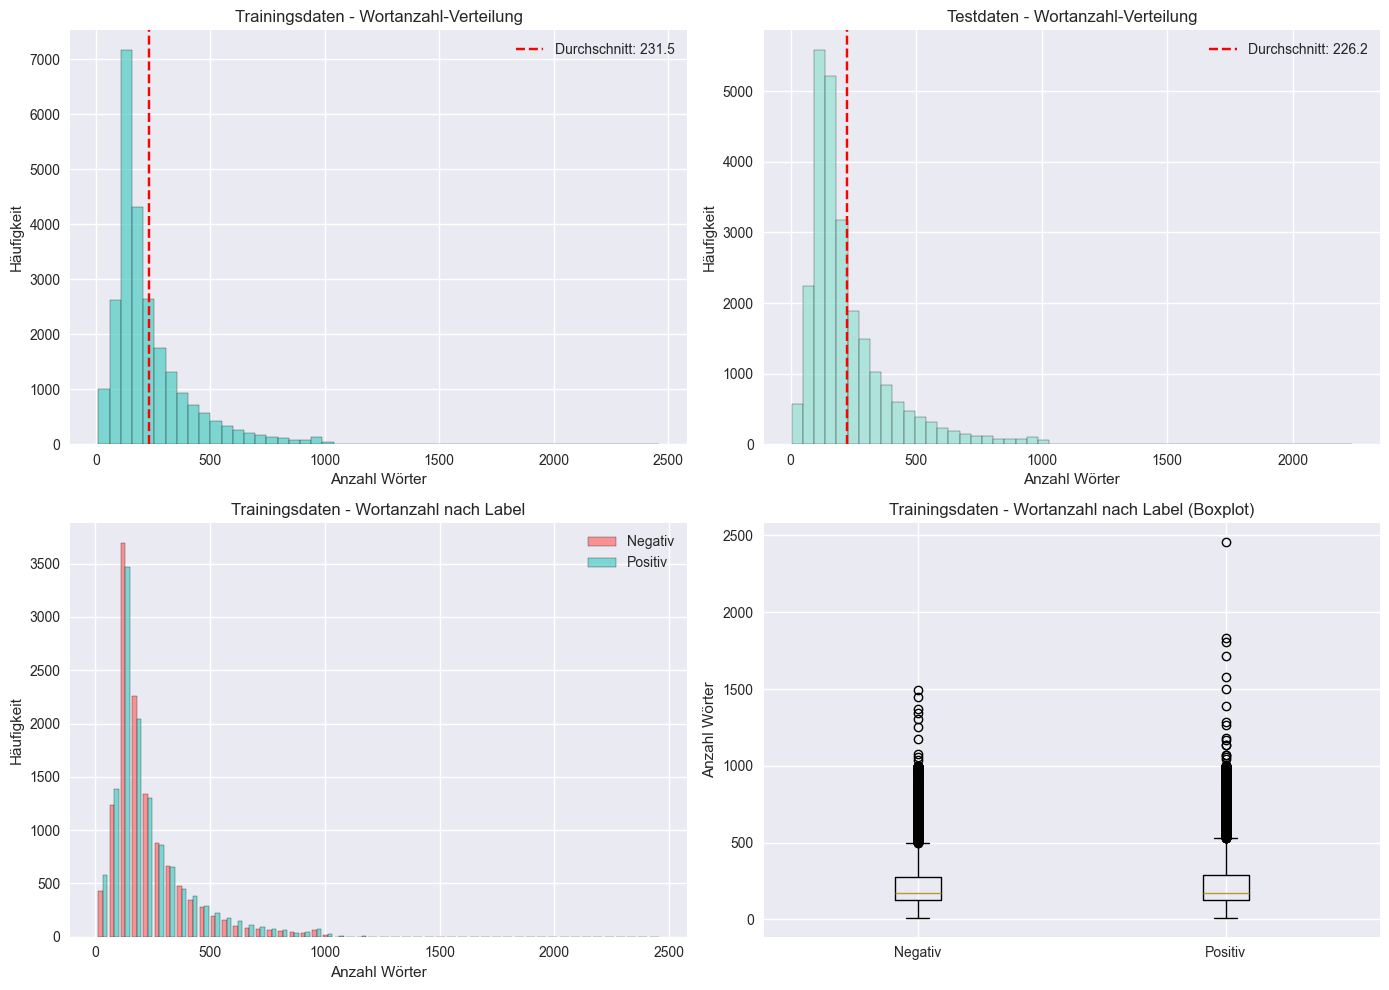

In [13]:
# Visualisierung der Textlängen-Verteilungen
# Erstelle ein 2x2 Grid für verschiedene Visualisierungen
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Histogramm: Wortanzahl-Verteilung für Trainingsdaten
if len(train_df) > 0 and "word_count" in train_df.columns:
    axes[0, 0].hist(train_df["word_count"], bins=50, alpha=0.7, color='#4ecdc4', edgecolor='black')
    axes[0, 0].axvline(train_df["word_count"].mean(), color='red', linestyle='--', 
                       label=f'Durchschnitt: {train_df["word_count"].mean():.1f}')
    axes[0, 0].set_title("Trainingsdaten - Wortanzahl-Verteilung")
    axes[0, 0].legend()
else:
    axes[0, 0].text(0.5, 0.5, "Keine Trainingsdaten", ha='center', va='center')
    axes[0, 0].set_title("Trainingsdaten - Wortanzahl-Verteilung")
axes[0, 0].set_xlabel("Anzahl Wörter")
axes[0, 0].set_ylabel("Häufigkeit")

# Histogramm: Wortanzahl-Verteilung für Testdaten
if len(test_df) > 0 and "word_count" in test_df.columns:
    axes[0, 1].hist(test_df["word_count"], bins=50, alpha=0.7, color='#95e1d3', edgecolor='black')
    axes[0, 1].axvline(test_df["word_count"].mean(), color='red', linestyle='--', 
                       label=f'Durchschnitt: {test_df["word_count"].mean():.1f}')
    axes[0, 1].set_title("Testdaten - Wortanzahl-Verteilung")
    axes[0, 1].legend()
else:
    axes[0, 1].text(0.5, 0.5, "Keine Testdaten", ha='center', va='center')
    axes[0, 1].set_title("Testdaten - Wortanzahl-Verteilung")
axes[0, 1].set_xlabel("Anzahl Wörter")
axes[0, 1].set_ylabel("Häufigkeit")

# Histogramm: Wortanzahl nach Label (Neg vs. Pos)
if len(train_df) > 0 and "word_count" in train_df.columns:
    train_pos = train_df[train_df["label"] == 1]["word_count"]
    train_neg = train_df[train_df["label"] == 0]["word_count"]
    if len(train_neg) > 0 or len(train_pos) > 0:
        data_to_hist = []
        labels_hist = []
        colors_hist = []
        if len(train_neg) > 0:
            data_to_hist.append(train_neg)
            labels_hist.append('Negativ')
            colors_hist.append('#ff6b6b')
        if len(train_pos) > 0:
            data_to_hist.append(train_pos)
            labels_hist.append('Positiv')
            colors_hist.append('#4ecdc4')
        axes[1, 0].hist(data_to_hist, bins=50, alpha=0.7, label=labels_hist, 
                        color=colors_hist, edgecolor='black')
        axes[1, 0].legend()
    else:
        axes[1, 0].text(0.5, 0.5, "Keine Daten", ha='center', va='center')
    axes[1, 0].set_title("Trainingsdaten - Wortanzahl nach Label")
else:
    axes[1, 0].text(0.5, 0.5, "Keine Trainingsdaten", ha='center', va='center')
    axes[1, 0].set_title("Trainingsdaten - Wortanzahl nach Label")
axes[1, 0].set_xlabel("Anzahl Wörter")
axes[1, 0].set_ylabel("Häufigkeit")

# Boxplot: Vergleich der Wortanzahl zwischen negativen und positiven Reviews
# Boxplots zeigen Median, Quartile und Ausreißer
if len(train_df) > 0 and "word_count" in train_df.columns:
    data_to_plot = []
    labels_box = []
    if len(train_df[train_df["label"] == 0]) > 0:
        data_to_plot.append(train_df[train_df["label"] == 0]["word_count"])
        labels_box.append('Negativ')
    if len(train_df[train_df["label"] == 1]) > 0:
        data_to_plot.append(train_df[train_df["label"] == 1]["word_count"])
        labels_box.append('Positiv')
    if len(data_to_plot) > 0:
        axes[1, 1].boxplot(data_to_plot, labels=labels_box)
    else:
        axes[1, 1].text(0.5, 0.5, "Keine Daten", ha='center', va='center')
    axes[1, 1].set_title("Trainingsdaten - Wortanzahl nach Label (Boxplot)")
else:
    axes[1, 1].text(0.5, 0.5, "Keine Trainingsdaten", ha='center', va='center')
    axes[1, 1].set_title("Trainingsdaten - Wortanzahl nach Label (Boxplot)")
axes[1, 1].set_ylabel("Anzahl Wörter")

plt.tight_layout()
plt.savefig(BASE_DIR / "outputs" / "text_characteristics.png", dpi=300, bbox_inches='tight')
plt.show()


## 1.4 Beispiel-Reviews


In [14]:
# Beispiel-Reviews anzeigen, um ein Gefühl für die Daten zu bekommen
if len(train_df) > 0:
    # Positives Review
    train_pos = train_df[train_df["label"] == 1]
    if len(train_pos) > 0:
        print("=== Beispiel: Positives Review ===")
        pos_example = train_pos.iloc[0]
        print(f"Label: {pos_example['label']} (1 = Positiv)")
        if "word_count" in pos_example:
            print(f"Länge: {len(pos_example['text'])} Zeichen, {pos_example['word_count']} Wörter")
        else:
            print(f"Länge: {len(pos_example['text'])} Zeichen")
        print(f"\nText (erste 500 Zeichen):\n{pos_example['text'][:500]}...")
    else:
        print("=== Beispiel: Positives Review ===")
        print(" Keine positiven Reviews in den Trainingsdaten vorhanden!")
    
    print("\n" + "="*80)
    
    # Negatives Review
    train_neg = train_df[train_df["label"] == 0]
    if len(train_neg) > 0:
        print("=== Beispiel: Negatives Review ===")
        neg_example = train_neg.iloc[0]
        print(f"Label: {neg_example['label']} (0 = Negativ)")
        if "word_count" in neg_example:
            print(f"Länge: {len(neg_example['text'])} Zeichen, {neg_example['word_count']} Wörter")
        else:
            print(f"Länge: {len(neg_example['text'])} Zeichen")
        print(f"\nText (erste 500 Zeichen):\n{neg_example['text'][:500]}...")
    else:
        print("=== Beispiel: Negatives Review ===")
        print(" Keine negativen Reviews in den Trainingsdaten vorhanden!")
else:
    print(" Keine Trainingsdaten vorhanden, um Beispiel-Reviews anzuzeigen!")


=== Beispiel: Positives Review ===
Label: 1 (1 = Positiv)
Länge: 2562 Zeichen, 453 Wörter

Text (erste 500 Zeichen):
In Panic In The Streets Richard Widmark plays U.S. Navy doctor who has his week rudely interrupted with a corpse that contains plague. As cop Paul Douglas properly points out the guy died from two bullets in the chest. That's not the issue here, the two of them become unwilling partners in an effort to find the killers and anyone else exposed to the disease.<br /><br />As was pointed out by any number of people, for some reason director Elia Kazan did not bother to cast the small parts with anyo...

=== Beispiel: Negatives Review ===
Label: 0 (0 = Negativ)
Länge: 704 Zeichen, 137 Wörter

Text (erste 500 Zeichen):
If you ask me the first one was really better one. Look at Sarah M. G., she is real, mean, cruel girl, look at Amy Adams she is just little fool hanging around. She is nothing! People don't adore her! Second, Sebastian was cute and hot in first movie, now he is 

## 1.5 Zusammenfassung

**Dataset-Charakteristika:**
- **Größe**: Train und Test Sets wurden geladen (siehe oben)
- **Balance**: Das Dataset ist balanciert (50% positive, 50% negative Reviews)
- **Durchschnittliche Wortanzahl**: Siehe oben berechnete Statistiken
- **Texttyp**: Film-Reviews (IMDB)
- **Klassen**: Binär (Positive/Negative Sentiment)
